In [1]:
import pandas as pd
import numpy as np
from plotnine import *

plain = theme_bw() + theme(
    panel_grid_major=element_blank(),
    panel_grid_minor=element_blank(),
    panel_border=element_blank(),
    panel_background=element_blank(),
)


## Building the Groups
Following Hargrove's method, I grouped murders by county, victim sex, and weapon, then compared how many each group actually solved with how many the model expected.

In [2]:
df = pd.read_csv("../data/scored.csv")
print(df.shape)

(793144, 17)


793,144 scored murders.

In [3]:
df.head()

,ID,CNTYFIPS,State,Agentype,Year,Month,VicAge,VicSex,VicRace,VicEthnic,Weapon,VicCount,solved,p_solved,p_casemix,p_as_white,fold
0,197609001AL00400,"Autauga, AL",Alabama,Sheriff,1976,September,30.0,Male,Black,Unknown or not reported,Other or type unknown,0,0,0.585552,0.659490,0.467747,0
1,197701001AL00400,"Autauga, AL",Alabama,Sheriff,1977,January,65.0,Female,Black,Unknown or not reported,Other or type unknown,0,1,0.710360,0.575851,0.520601,2
2,197703001AL00400,"Autauga, AL",Alabama,Sheriff,1977,March,48.0,Male,White,Unknown or not reported,"Handgun - pistol, revolver, etc",0,1,0.878045,0.896676,0.878045,4
3,197703001AL00401,"Autauga, AL",Alabama,Municipal police,1977,March,27.0,Male,Black,Unknown or not reported,Shotgun,0,1,0.964655,0.946454,0.948538,3
4,197708001AL00400,"Autauga, AL",Alabama,Sheriff,1977,August,17.0,Female,Black,Unknown or not reported,Knife or cutting instrument,0,1,0.851718,0.904176,0.602369,1


In [4]:
df["Weapon"].value_counts()

Weapon
Handgun - pistol, revolver, etc         390187
Knife or cutting instrument             117772
Firearm, type not stated                 68129
Personal weapons, includes beating       45499
Other or type unknown                    38978
Shotgun                                  38120
Blunt object - hammer, club, etc         35553
Rifle                                    29080
Strangulation - hanging                  10019
Fire                                      7471
Asphyxiation - includes death by gas      4687
Other gun                                 3054
Narcotics or drugs, sleeping pills        1951
Drowning                                  1255
Explosives                                 603
Poison - does not include gas              538
Pushed or thrown out window                248
Name: count, dtype: int64

I combined the two strangulation codes since they're basically the same method.

In [5]:
df["Weapon"] = df["Weapon"].replace({"Strangulation - hanging": "Strangulation", "Asphyxiation - includes death by gas": "Strangulation"})
df["Weapon"].value_counts()

Weapon
Handgun - pistol, revolver, etc       390187
Knife or cutting instrument           117772
Firearm, type not stated               68129
Personal weapons, includes beating     45499
Other or type unknown                  38978
Shotgun                                38120
Blunt object - hammer, club, etc       35553
Rifle                                  29080
Strangulation                          14706
Fire                                    7471
Other gun                               3054
Narcotics or drugs, sleeping pills      1951
Drowning                                1255
Explosives                               603
Poison - does not include gas            538
Pushed or thrown out window              248
Name: count, dtype: int64

That gives 14,706 strangulations.

The z-score is actual minus expected solved, divided by how much random variation is normal for a group that size. A very negative z means far fewer solved than expected.

In [6]:
df["n_in_incident"] = df.groupby("ID")["ID"].transform("size")
df["variance"] = df["n_in_incident"] * df["p_solved"] * (1 - df["p_solved"])
df["unsolved_inc"] = (1 - df["solved"]) / df["n_in_incident"]

clusters = df.groupby(["CNTYFIPS", "VicSex", "Weapon"])[["solved", "p_solved"]].sum()
clusters["n_murders"] = df.groupby(["CNTYFIPS", "VicSex", "Weapon"])["solved"].count()
clusters["z_score"] = (clusters["solved"] - clusters["p_solved"]) / np.sqrt(df.groupby(["CNTYFIPS", "VicSex", "Weapon"])["variance"].sum())
clusters = clusters.reset_index()
clusters = clusters.rename(columns={"solved": "actual_solved", "p_solved": "expected_solved"})

clusters["n_unsolved"] = clusters["n_murders"] - clusters["actual_solved"]
clusters["n_unsolved_inc"] = df.groupby(["CNTYFIPS", "VicSex", "Weapon"])["unsolved_inc"].sum().values

print(clusters.shape)
clusters.head()

(39059, 9)


,CNTYFIPS,VicSex,Weapon,actual_solved,expected_solved,n_murders,z_score,n_unsolved,n_unsolved_inc
0,"Abbeville, SC",Female,Fire,1,0.865596,1,0.394048,0,0.0
1,"Abbeville, SC",Female,"Firearm, type not stated",1,1.340087,2,-0.417484,1,1.0
2,"Abbeville, SC",Female,"Handgun - pistol, revolver, etc",8,7.746729,8,0.441904,0,0.0
3,"Abbeville, SC",Female,Knife or cutting instrument,5,4.701506,5,0.467596,0,0.0
4,"Abbeville, SC",Female,Other or type unknown,1,0.556277,1,0.893121,0,0.0


39,059 groups.

## Filtering and County Adjustment
A group with only one or two unsolved murders can't really be a cluster, so I kept groups with at least 5 separate unsolved incidents. That way one fire or shooting with a lot of victims only counts once.

In [7]:
candidates = clusters[clusters["n_unsolved_inc"] >= 5]
print(candidates.shape)
candidates.sort_values("z_score").head(20)

(3512, 9)


,CNTYFIPS,VicSex,Weapon,actual_solved,expected_solved,n_murders,z_score,n_unsolved,n_unsolved_inc
9053,"Dallas, TX",Male,"Handgun - pistol, revolver, etc",3981,4622.454173,5904,-19.549131,1923,1850.833333
12556,"Fulton, GA",Male,"Handgun - pistol, revolver, etc",2214,2797.466920,4330,-18.679382,2116,2071.833333
29952,"Richmond, VA",Male,"Handgun - pistol, revolver, etc",859,1151.178343,1614,-15.724536,755,727.100000
9052,"Dallas, TX",Male,"Firearm, type not stated",516,837.090841,1706,-15.365729,1190,1149.250000
26777,"Orleans, LA",Male,"Handgun - pistol, revolver, etc",2777,3313.562293,5527,-14.440875,2750,2661.666667
598,"Allegheny, PA",Male,"Handgun - pistol, revolver, etc",742,963.917139,1439,-12.771104,697,673.500000
19254,"Lake, IN",Male,"Handgun - pistol, revolver, etc",1077,1349.842253,2143,-11.889799,1066,1018.500000
31000,"San Francisco, CA",Male,"Handgun - pistol, revolver, etc",754,970.664327,1652,-10.880675,898,876.333333
9054,"Dallas, TX",Male,Knife or cutting instrument,878,1014.043173,1253,-9.762397,375,367.833333
11244,"Essex, NJ",Male,"Handgun - pistol, revolver, etc",1394,1673.291063,3329,-9.723139,1935,1887.083333


3,512 groups left, and the top 20 is almost all male handgun murders in big cities like Dallas, Atlanta, and Richmond. Those counties solve fewer murders across the board, so every group there looks bad. That's the place, not a serial killer.

To fix that, I compared each group to the rest of its own county, leaving the group itself out so a real cluster can't pull down its own county's rate.

In [8]:
clusters["variance"] = df.groupby(["CNTYFIPS", "VicSex", "Weapon"])["variance"].sum().values

county = clusters.groupby("CNTYFIPS")[["actual_solved", "expected_solved"]].sum()
clusters["county_actual"] = clusters["CNTYFIPS"].map(county["actual_solved"])
clusters["county_expected"] = clusters["CNTYFIPS"].map(county["expected_solved"])

clusters["county_ratio"] = (clusters["county_actual"] - clusters["actual_solved"]) / (clusters["county_expected"] - clusters["expected_solved"])
clusters["adj_expected"] = clusters["expected_solved"] * clusters["county_ratio"]
clusters["adj_z_score"] = (clusters["actual_solved"] - clusters["adj_expected"]) / np.sqrt(clusters["variance"])

candidates = clusters[clusters["n_unsolved_inc"] >= 5]
candidates.sort_values("adj_z_score").head(20)

,CNTYFIPS,VicSex,Weapon,actual_solved,expected_solved,n_murders,z_score,n_unsolved,n_unsolved_inc,variance,county_actual,county_expected,county_ratio,adj_expected,adj_z_score
598,"Allegheny, PA",Male,"Handgun - pistol, revolver, etc",742,963.917139,1439,-12.771104,697,673.500000,301.942877,2019,2260.646734,0.984785,949.251249,-11.927097
9052,"Dallas, TX",Male,"Firearm, type not stated",516,837.090841,1706,-15.365729,1190,1149.250000,436.666125,8454,9969.948674,0.869169,727.573692,-10.124811
20228,"Lehigh, PA",Male,"Handgun - pistol, revolver, etc",85,140.791917,189,-9.257332,104,101.000000,36.322093,343,402.900740,0.984324,138.584861,-8.891124
24435,"Montgomery, AL",Male,"Firearm, type not stated",29,77.419360,157,-8.085687,128,128.000000,35.859497,885,1013.851819,0.914108,70.769623,-6.975229
12556,"Fulton, GA",Male,"Handgun - pistol, revolver, etc",2214,2797.466920,4330,-18.679382,2116,2071.833333,975.680132,4368,5277.810614,0.868428,2429.398700,-6.895874
29952,"Richmond, VA",Male,"Handgun - pistol, revolver, etc",859,1151.178343,1614,-15.724536,755,727.100000,345.255325,1953,2436.047420,0.851449,980.169209,-6.521118
11107,"Erie, NY",Male,"Handgun - pistol, revolver, etc",241,356.178478,783,-8.115760,542,528.250000,201.411500,1128,1317.819126,0.922382,328.532608,-6.167764
4740,"Cameron, TX",Male,"Handgun - pistol, revolver, etc",196,216.659172,282,-2.790556,86,81.000000,54.808060,532,520.264844,1.106699,239.776422,-5.913138
37431,"Webb, TX",Male,"Handgun - pistol, revolver, etc",145,165.390724,214,-3.094217,69,63.000000,43.427389,423,417.388921,1.103182,182.456153,-5.683833
33052,"St. Louis city, MO",Male,"Firearm, type not stated",452,662.062332,2150,-9.716056,1698,1654.466667,467.429782,3489,4214.664787,0.854866,565.974755,-5.271697


Then I focused on murders of women, since that's where Hargrove's method looks for serial killers.

In [9]:
print(candidates["adj_z_score"].isna().sum())

female = candidates[candidates["VicSex"] == "Female"]
print(female.shape)
female.sort_values("adj_z_score").head(20)

0
(1197, 15)


,CNTYFIPS,VicSex,Weapon,actual_solved,expected_solved,n_murders,z_score,n_unsolved,n_unsolved_inc,variance,county_actual,county_expected,county_ratio,adj_expected,adj_z_score
9170,"Dauphin, PA",Female,"Personal weapons, includes beating",9,15.204185,18,-3.931036,9,8.000000,2.490895,505,470.880297,1.088492,16.549640,-4.783530
33253,"Stanislaus, CA",Female,"Handgun - pistol, revolver, etc",57,59.631896,72,-0.781791,15,15.000000,11.333278,979,833.341582,1.191661,71.061031,-4.176759
34293,"Tarrant, TX",Female,Rifle,26,33.777691,37,-4.084918,11,9.700000,3.625223,4087,4083.176745,1.002865,33.874459,-4.135742
17024,"Jackson, MO",Female,Strangulation,34,46.815578,94,-2.807654,60,59.000000,20.834800,3771,3414.555200,1.109646,51.948735,-3.932232
9036,"Dallas, TX",Female,"Firearm, type not stated",77,122.489381,209,-6.305787,132,126.750000,52.040503,8454,9969.948674,0.850676,104.198811,-3.770328
24424,"Montgomery, AL",Female,"Firearm, type not stated",6,19.490174,38,-4.495138,32,32.000000,9.006354,885,1013.851819,0.883984,17.229007,-3.741682
11800,"Floyd, GA",Female,Other or type unknown,1,3.851638,6,-2.716789,5,5.000000,1.101735,244,203.176502,1.219115,4.695591,-3.520833
25559,"New York, NY",Female,"Personal weapons, includes beating",673,752.247959,1285,-4.593007,612,598.666667,297.702103,23346,24064.232964,0.972590,731.628730,-3.397970
26613,"Orange, FL",Female,"Personal weapons, includes beating",71,78.435824,91,-2.278490,20,19.000000,10.650348,2128,2050.534126,1.043051,81.812600,-3.313205
29189,"Pulaski, MO",Female,Other or type unknown,1,6.168958,8,-4.463997,7,6.500000,1.340782,39,54.674858,0.783410,4.832823,-3.310088


1,197 female-victim groups. Jackson County, MO strangulations ranked 4th, which matches Lorenzo Gilyard's Kansas City murders.

In [10]:
clusters.to_csv("../data/clusters.csv", index=False)
print(clusters.shape)

(39059, 15)


## Top Flagged Groups
I charted the top 15 to see what kinds of groups get flagged.

In [11]:
top_female = female.sort_values("adj_z_score").head(15).copy()
top_female["Weapon"] = top_female["Weapon"].replace({"Personal weapons, includes beating": "Beating", "Handgun - pistol, revolver, etc": "Handgun", "Firearm, type not stated": "Firearm (unspecified)", "Knife or cutting instrument": "Knife", "Other or type unknown": "Other/unknown", "Blunt object - hammer, club, etc": "Blunt object"})


In [12]:
creepy_15 = [
    "#8A0303", "#3B5249", "#5C3A6B", "#C8963E", "#38618C",
    "#B53737", "#6B8E4E", "#8D6A9F", "#D96B27", "#5BC0BE",
    "#4A151B", "#A3B18A", "#2E294E", "#D8CFC4", "#736B60"
]


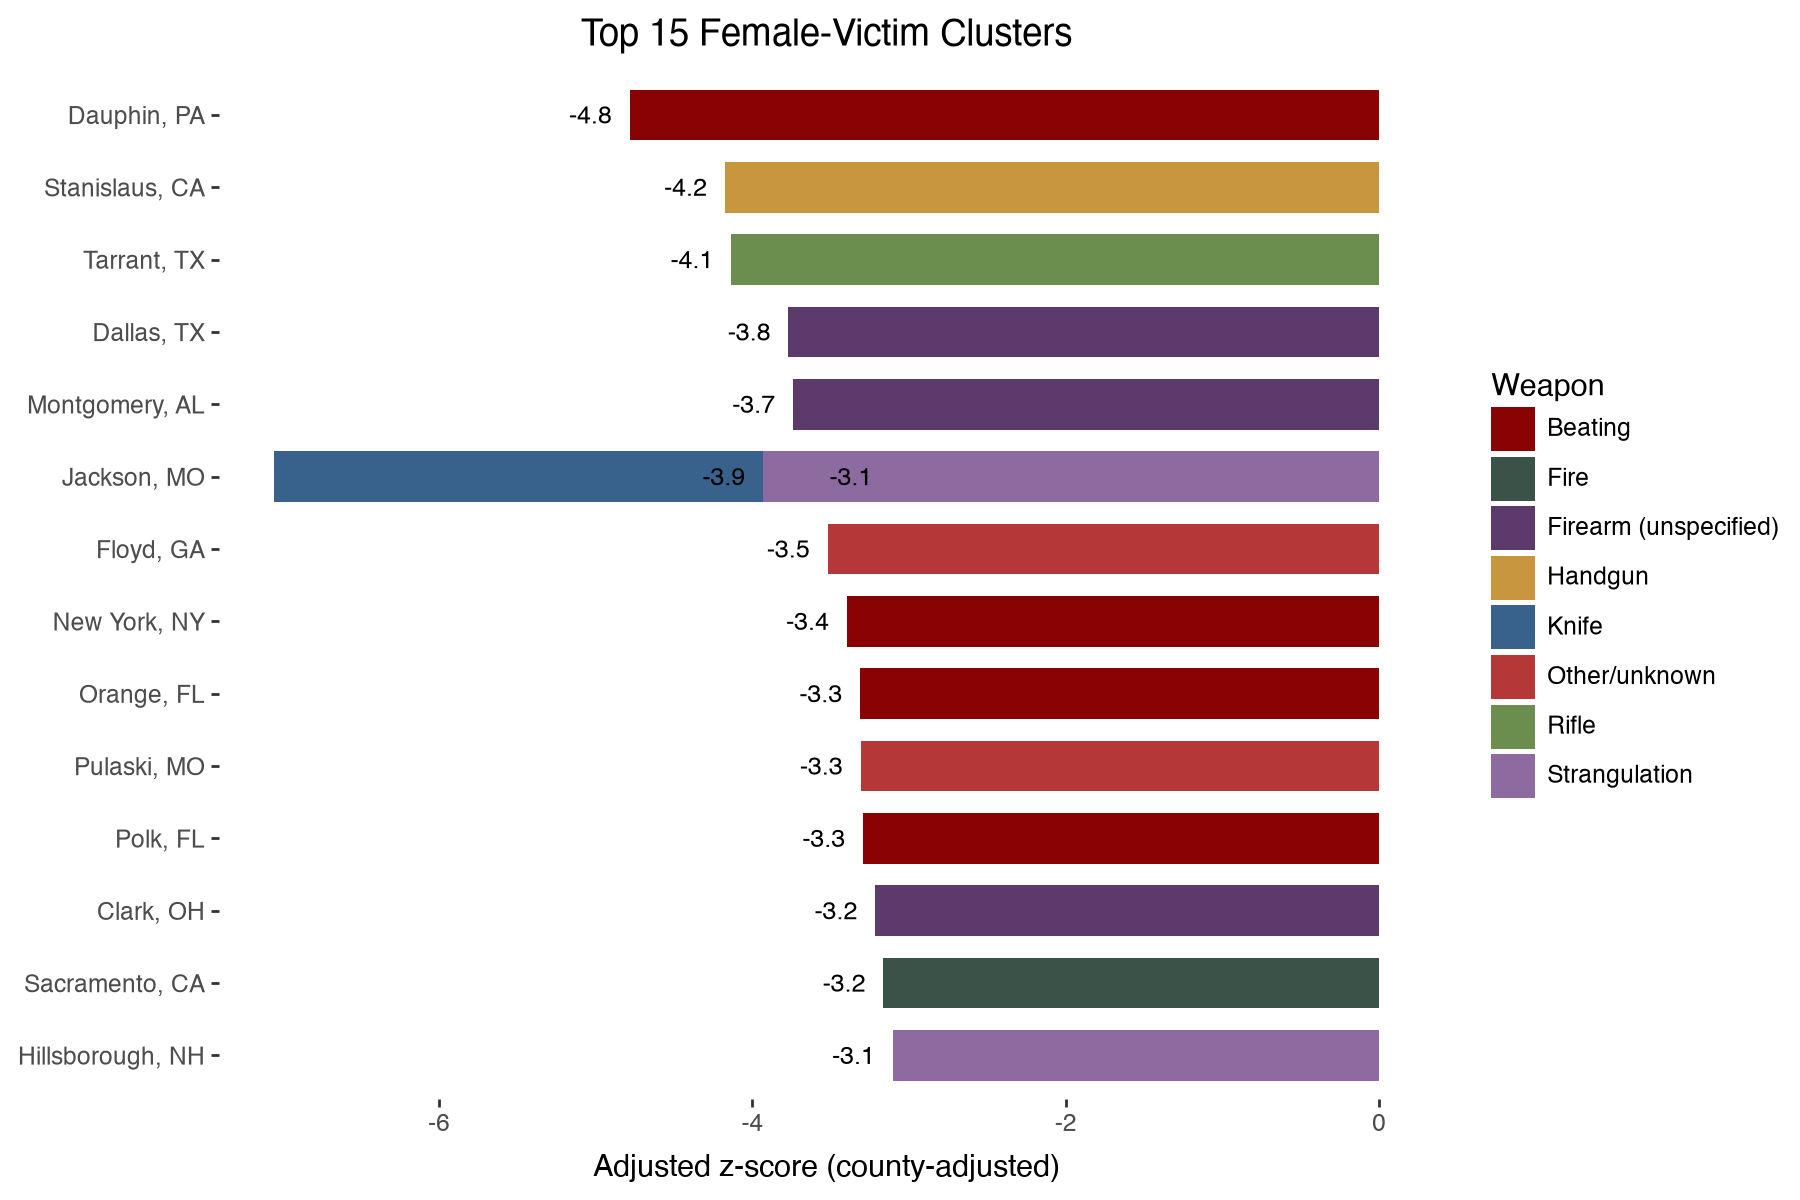

In [13]:
(ggplot(top_female, aes(x="reorder(CNTYFIPS, -adj_z_score)", y="adj_z_score", fill='Weapon'))
 + geom_col(width=0.7)
 + geom_text(aes(label="round(adj_z_score, 1)"), nudge_y=-0.25, size=9)
 + coord_flip()
 + scale_fill_manual(values=creepy_15)
 + plain
 + theme(figure_size=(9, 6))
 + labs(title="Top 15 Female-Victim Clusters",
        x="", y="Adjusted z-score (county-adjusted)", fill="Weapon"))

Scores run from about −4.8 to −3.1, so no single group stands way out. The list mixes small counties like Floyd, GA with big ones like New York and Dallas, and lots of different weapons, which is what I'd expect after adjusting for county. A low score just means a group is worth a closer look.